In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

In [2]:
df = pd.read_csv("data/raw/credit_risk.csv")

In [3]:
df.head()

,customer_id,age,monthly_income,employment_years,credit_score,existing_debt,loan_amount,late_payments,employment_type,housing_status,loan_purpose,high_risk
0,10001,59,37793.13,9.7,594.0,55164.03,122663.77,1,Self-employed,Family,Home,1
1,10002,29,41391.57,4.3,737.0,39200.65,105733.52,1,Full-time,Rent,Vehicle,0
2,10003,22,43617.89,1.0,739.0,13227.44,133019.25,0,Unemployed,Family,Home,0
3,10004,49,37354.71,5.9,569.0,47330.52,27947.26,0,Full-time,Own,Personal,0
4,10005,37,54096.04,10.8,692.0,21720.79,226420.59,2,Full-time,Rent,Education,0


In [16]:
df.tail()

,customer_id,age,monthly_income,employment_years,credit_score,existing_debt,loan_amount,late_payments,employment_type,housing_status,loan_purpose,high_risk
1195,11196,38,62513.79,8.8,757.0,47031.08,237847.36,2,Part-time,Rent,Home,1
1196,11197,33,52428.58,5.6,622.0,47688.71,63429.00,2,Self-employed,Own,Home,1
1197,11198,62,26824.30,6.1,739.0,68657.46,218793.24,2,Full-time,Own,Education,1
1198,11199,41,53993.58,1.3,733.0,26537.27,280431.21,0,Full-time,Own,Business,1
1199,11200,23,25708.76,9.8,598.0,23599.63,178135.50,3,Self-employed,Rent,Education,1


In [5]:
df.shape

(1200, 12)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       1200 non-null   int64  
 1   age               1200 non-null   int64  
 2   monthly_income    1152 non-null   float64
 3   employment_years  1164 non-null   float64
 4   credit_score      1164 non-null   float64
 5   existing_debt     1200 non-null   float64
 6   loan_amount       1200 non-null   float64
 7   late_payments     1200 non-null   int64  
 8   employment_type   1176 non-null   object 
 9   housing_status    1176 non-null   object 
 10  loan_purpose      1200 non-null   object 
 11  high_risk         1200 non-null   int64  
dtypes: float64(5), int64(4), object(3)
memory usage: 112.6+ KB


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_id,1200.0,10600.500000,346.554469,10001.00,10300.7500,10600.500,10900.2500,11200.00
age,1200.0,42.751667,12.939005,21.00,32.0000,42.000,54.0000,65.00
monthly_income,1152.0,41476.512795,14457.488052,12000.00,31291.5525,41271.935,51775.2075,92002.91
employment_years,1164.0,7.479897,4.723410,0.20,3.9000,6.700,10.0000,30.90
credit_score,1164.0,653.591065,87.501998,379.00,595.0000,657.000,713.0000,900.00
existing_debt,1200.0,39602.141908,27531.456432,857.05,19103.2850,33779.565,53522.4100,207201.57
loan_amount,1200.0,157983.427800,84352.885939,10068.67,84451.4625,161398.500,232383.2375,299930.01
late_payments,1200.0,1.211667,1.085286,0.00,0.0000,1.000,2.0000,6.00
high_risk,1200.0,0.522500,0.499702,0.00,0.0000,1.000,1.0000,1.00


In [7]:
df.isnull().sum()

customer_id          0
age                  0
monthly_income      48
employment_years    36
credit_score        36
existing_debt        0
loan_amount          0
late_payments        0
employment_type     24
housing_status      24
loan_purpose         0
high_risk            0
dtype: int64

In [8]:
print(df["high_risk"].value_counts())

high_risk
1    627
0    573
Name: count, dtype: int64


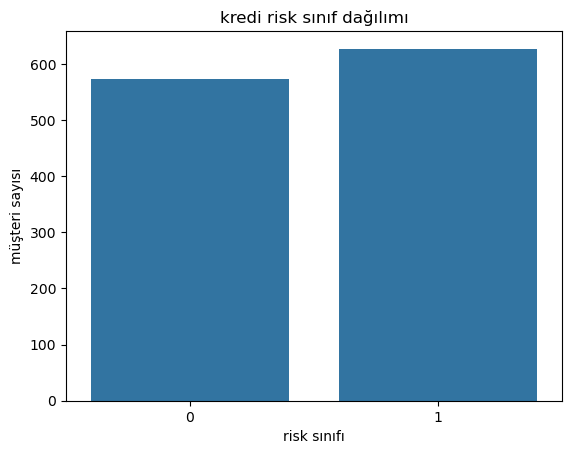

In [9]:
sns.countplot(data=df,x="high_risk")
plt.title("kredi risk sınıf dağılımı")
plt.xlabel("risk sınıfı")
plt.ylabel("müşteri sayısı")
plt.show()

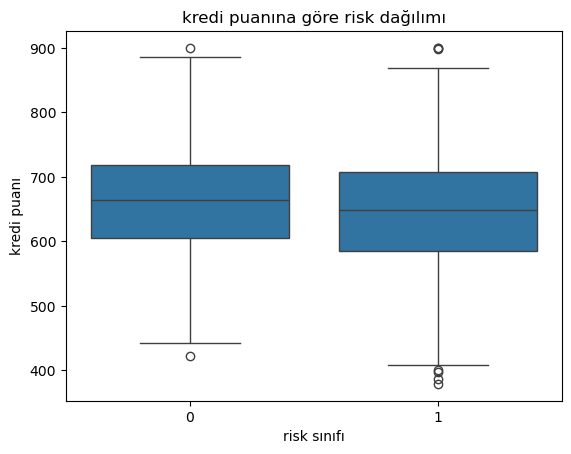

In [10]:
sns.boxplot(data=df,
           x="high_risk",
           y="credit_score")
plt.title("kredi puanına göre risk dağılımı")
plt.xlabel("risk sınıfı")
plt.ylabel("kredi puanı")
plt.show()

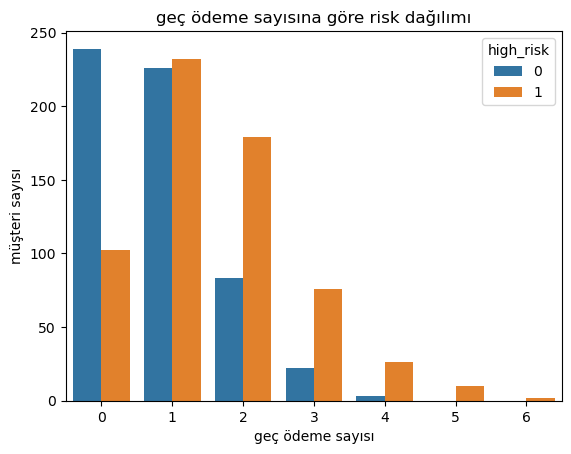

In [15]:
sns.countplot(
    data=df,
    x="late_payments",
    hue="high_risk"
)
plt.title("geç ödeme sayısına göre risk dağılımı")
plt.xlabel("geç ödeme sayısı")
plt.ylabel("müşteri sayısı")
plt.show()

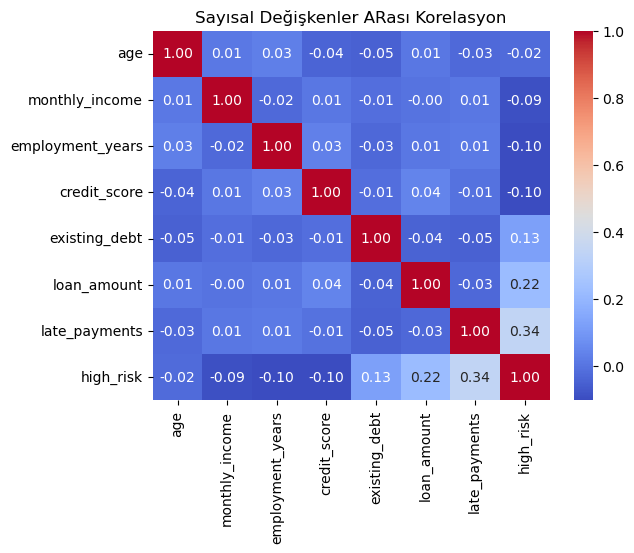

In [17]:
numeric_df = df.select_dtypes(include="number")

sns.heatmap(
    numeric_df.drop(columns=["customer_id"]).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Sayısal Değişkenler ARası Korelasyon")
plt.show()

In [18]:
X = df.drop(columns=["high_risk","customer_id"])
y = df["high_risk"]

print(X.shape)
print(y.shape)

(1200, 10)
(1200,)


In [19]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [20]:
df.columns

Index(['customer_id', 'age', 'monthly_income', 'employment_years',
       'credit_score', 'existing_debt', 'loan_amount', 'late_payments',
       'employment_type', 'housing_status', 'loan_purpose', 'high_risk'],
      dtype='object')

In [21]:
numeric_features = [
    "age",
    "monthly_income",
    "employment_years",
    "credit_score",
    "existing_debt",
    "loan_amount",
    "late_payments"
]

categorical_features = [
    "employment_years",
    "housing_status",
    "loan_purpose"
]

In [22]:
numeric_transformer = Pipeline(
    steps = [
        ("imputer",SimpleImputer(strategy="median")),
        ("scaler",StandardScaler())
    ]
)

In [23]:
categorical_tranformer = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="most_frequent")),
        ("onehot",OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [28]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num",numeric_transformer,numeric_features),
        ("cat",categorical_tranformer,categorical_features)
    ]
)

In [29]:
model = Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("classifier",LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

In [30]:
model.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [31]:
y_pred = model.predict(X_test)
print(y_pred[:10])


[0 0 0 0 1 1 1 1 0 0]


In [33]:
y_probability = model.predict_proba(X_test)
print(y_probability[:10])

[[0.71001657 0.28998343]
 [0.82843429 0.17156571]
 [0.93690258 0.06309742]
 [0.77256677 0.22743323]
 [0.36879947 0.63120053]
 [0.47289239 0.52710761]
 [0.40538165 0.59461835]
 [0.06464392 0.93535608]
 [0.70330306 0.29669694]
 [0.61247621 0.38752379]]


In [34]:
risk_score = model.predict_proba(X_test)[:,1]
print(risk_score[:10])

[0.28998343 0.17156571 0.06309742 0.22743323 0.63120053 0.52710761
 0.59461835 0.93535608 0.29669694 0.38752379]


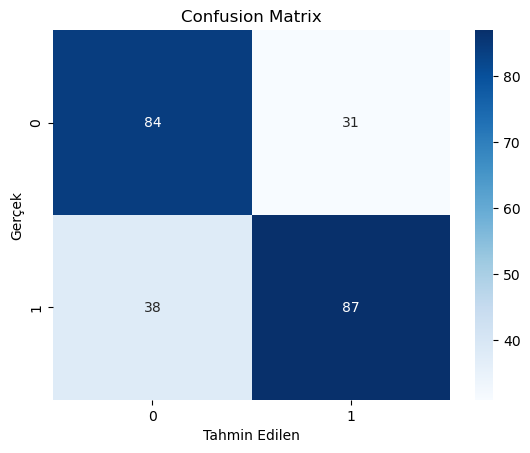

In [37]:
cm = confusion_matrix(y_test,y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.xlabel("Tahmin Edilen")
plt.ylabel("Gerçek")
plt.title("Confusion Matrix")
plt.show()

In [38]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

Accuracy: 0.7125
Precision: 0.7373
Recall: 0.696
F1 Score: 0.716


In [39]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Dusuk Risk","Yuksek Risk"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

  Dusuk Risk       0.69      0.73      0.71       115
 Yuksek Risk       0.74      0.70      0.72       125

    accuracy                           0.71       240
   macro avg       0.71      0.71      0.71       240
weighted avg       0.71      0.71      0.71       240



In [ ]:
0.50 > 1
0.50 < 0

In [40]:
df.columns

Index(['customer_id', 'age', 'monthly_income', 'employment_years',
       'credit_score', 'existing_debt', 'loan_amount', 'late_payments',
       'employment_type', 'housing_status', 'loan_purpose', 'high_risk'],
      dtype='object')

In [41]:
new_customer = pd.DataFrame({
    "age":[32],
    "monthly_income":[35000],
    "employment_years":[3],
    "credit_score":[598],
    "existing_debt":[45000],
    "loan_amount":[120000],
    "late_payments":[3],
    "employment_type":["Full-time"],
    "housing_status":["Rent"],
    "loan_purpose":["Vehicle"]
})

In [42]:
customer_probability = model.predict_proba(
    new_customer
)[0,1]
print("Yüksek Risk Olasılığı",round(customer_probability,4))

Yüksek Risk Olasılığı 0.9135
